In [12]:
from src.campaigns import generate_clean_campaigns
import numpy as np
import pandas as pd
import os
from sklearn.feature_extraction.text import TfidfVectorizer

In [2]:
clean_campaigns, entity_catalog = (
    generate_clean_campaigns(
        n_campaigns=1000,
        seed=42
    )
)

print(
    "Number of campaigns:",
    clean_campaigns["campaign_id"].nunique()
)

print(
    "Number of messages:",
    len(clean_campaigns)
)

print(
    "Average messages per campaign:",
    clean_campaigns.groupby(
        "campaign_id"
    ).size().mean()
)

display(
    clean_campaigns.head(10)
)

Number of campaigns: 1000
Number of messages: 6949
Average messages per campaign: 6.949


,campaign_id,message_id,message_order,timestamp,channel,sender,recipient,text,entity_id,reference_id,parent_message_id
0,C0001,C0001_M01,1,2026-03-18 13:19:00,whatsapp,advisor_20,client_0001,"Hi Daniel Vega, here is the summary for your r...",E0001,NaN,NaN
1,C0001,C0001_M02,2,2026-03-18 15:14:00,whatsapp,client_0001,advisor_20,"Thanks, I received the information.",E0001,NaN,C0001_M01
2,C0001,C0001_M03,3,2026-03-18 16:49:00,email,advisor_20,client_0001,Following up here on the whatsapp message I se...,E0001,C0001_M01,C0001_M02
3,C0001,C0001_M04,4,2026-03-18 17:53:00,whatsapp,client_0001,advisor_20,I reviewed the information and I have a questi...,E0001,NaN,C0001_M03
4,C0001,C0001_M05,5,2026-03-18 19:46:00,whatsapp,advisor_20,client_0001,"Certainly, Daniel Vega. I will explain that in...",E0001,NaN,C0001_M04
5,C0001,C0001_M06,6,2026-03-18 20:41:00,email,client_0001,advisor_20,That makes sense. Thank you.,E0001,NaN,C0001_M05
6,C0001,C0001_M07,7,2026-03-18 21:02:00,whatsapp,advisor_20,client_0001,Let me know if you need any additional informa...,E0001,NaN,C0001_M06
7,C0002,C0002_M01,1,2026-06-03 09:38:00,whatsapp,advisor_01,client_0002,"Hello Thomas Foster, I am sharing the initial ...",E0002,NaN,NaN
8,C0002,C0002_M02,2,2026-06-03 10:27:00,email,client_0002,advisor_01,Thank you. I will review it.,E0002,NaN,C0002_M01
9,C0002,C0002_M03,3,2026-06-03 12:02:00,sms,advisor_01,client_0002,Following up here on the whatsapp message I se...,E0002,C0002_M01,C0002_M02


inspeccionar una campaña completa 

In [3]:
example_campaign = (
    clean_campaigns[
        clean_campaigns["campaign_id"]
        == "C0001"
    ]
)

display(
    example_campaign[
        [
            "message_order",
            "timestamp",
            "channel",
            "sender",
            "recipient",
            "text",
            "reference_id",
            "parent_message_id"
        ]
    ]
)

,message_order,timestamp,channel,sender,recipient,text,reference_id,parent_message_id
0,1,2026-03-18 13:19:00,whatsapp,advisor_20,client_0001,"Hi Daniel Vega, here is the summary for your r...",NaN,NaN
1,2,2026-03-18 15:14:00,whatsapp,client_0001,advisor_20,"Thanks, I received the information.",NaN,C0001_M01
2,3,2026-03-18 16:49:00,email,advisor_20,client_0001,Following up here on the whatsapp message I se...,C0001_M01,C0001_M02
3,4,2026-03-18 17:53:00,whatsapp,client_0001,advisor_20,I reviewed the information and I have a questi...,NaN,C0001_M03
4,5,2026-03-18 19:46:00,whatsapp,advisor_20,client_0001,"Certainly, Daniel Vega. I will explain that in...",NaN,C0001_M04
5,6,2026-03-18 20:41:00,email,client_0001,advisor_20,That makes sense. Thank you.,NaN,C0001_M05
6,7,2026-03-18 21:02:00,whatsapp,advisor_20,client_0001,Let me know if you need any additional informa...,NaN,C0001_M06


In [6]:
validation = []

for campaign_id, group in clean_campaigns.groupby(
    "campaign_id"
):

    group = group.sort_values(
        "message_order"
    )

    # ---------------------------------
    # Correct message order
    # ---------------------------------

    expected_order = list(
        range(1, len(group) + 1)
    )

    valid_order = (
        group["message_order"].tolist()
        == expected_order
    )

    # ---------------------------------
    # Strictly increasing timestamps
    # ---------------------------------

    time_differences = (
        group["timestamp"]
        .diff()
        .dropna()
    )

    valid_timing = (
        time_differences
        > pd.Timedelta(0)
    ).all()

    # ---------------------------------
    # At least two channels
    # ---------------------------------

    valid_channels = (
        group["channel"].nunique()
        >= 2
    )

    # ---------------------------------
    # One stable entity
    # ---------------------------------

    valid_entity = (
        group["entity_id"].nunique()
        == 1
    )

    # ---------------------------------
    # At least one reference
    # ---------------------------------

    valid_reference_exists = (
        group["reference_id"]
        .notna()
        .any()
    )

    # ---------------------------------
    # Validate reference targets
    # ---------------------------------

    valid_reference_targets = True
    valid_cross_channel = True

    for _, row in group.iterrows():

        if pd.notna(
            row["reference_id"]
        ):

            target = group[
                group["message_id"]
                == row["reference_id"]
            ]

            if target.empty:

                valid_reference_targets = False
                valid_cross_channel = False
                continue

            target_row = target.iloc[0]

            if (
                target_row["message_order"]
                >= row["message_order"]
            ):
                valid_reference_targets = False

            if (
                target_row["channel"]
                == row["channel"]
            ):
                valid_cross_channel = False

    validation.append({
        "campaign_id": campaign_id,
        "valid_order": valid_order,
        "valid_timing": valid_timing,
        "valid_channels": valid_channels,
        "valid_entity": valid_entity,
        "valid_reference_exists":
            valid_reference_exists,
        "valid_reference_targets":
            valid_reference_targets,
        "valid_cross_channel":
            valid_cross_channel
    })


validation_df = pd.DataFrame(
    validation
)

display(
    validation_df.head()
)

,campaign_id,valid_order,valid_timing,valid_channels,valid_entity,valid_reference_exists,valid_reference_targets,valid_cross_channel
0,C0001,True,True,True,True,True,True,True
1,C0002,True,True,True,True,True,True,True
2,C0003,True,True,True,True,True,True,True
3,C0004,True,True,True,True,True,True,True
4,C0005,True,True,True,True,True,True,True


In [7]:
validation_summary = (
    validation_df
    .drop(columns="campaign_id")
    .mean()
)

display(
    validation_summary
)

valid_order                1.0
valid_timing               1.0
valid_channels             1.0
valid_entity               1.0
valid_reference_exists     1.0
valid_reference_targets    1.0
valid_cross_channel        1.0
dtype: float64

In [9]:
display(
    entity_catalog.head()
)

,entity_id,canonical_name,client_id
0,E0001,Daniel Vega,client_0001
1,E0002,Thomas Foster,client_0002
2,E0003,Julia Collins,client_0003
3,E0004,Olivia Bailey,client_0004
4,E0005,Sara Castro,client_0005


In [11]:
os.makedirs(
    "../data/processed",
    exist_ok=True
)

clean_campaigns.to_csv(
    "../data/processed/clean_structured_campaigns.csv",
    index=False
)

entity_catalog.to_csv(
    "../data/processed/entity_catalog.csv",
    index=False
)

validation_df.to_csv(
    "../results/clean_campaign_validation.csv",
    index=False
)

print(
    "Clean structured campaign dataset saved."
)

Clean structured campaign dataset saved.


In [13]:
from src.representations import (
    make_tfidf_vectorizer,
    generic_structural_summary
)

In [14]:
# test example campaign
example_campaign = (
    clean_campaigns[
        clean_campaigns["campaign_id"]
        == "C0001"
    ]
)

example_summary = (
    generic_structural_summary(
        example_campaign
    )
)

display(example_summary)

n_messages                  7.000000
campaign_duration         463.000000
mean_time_gap              77.166667
median_time_gap            79.500000
std_time_gap               33.795545
n_channels                  2.000000
channel_switch_rate         0.666667
channel_entropy             0.863121
dominant_channel_share      0.714286
mean_message_length        58.714286
std_message_length         23.553673
mean_token_count           10.285714
std_token_count             4.398516
dtype: float64

In [15]:
# tranform the 1k campaigns in one row of 13features
structural_records = []

for campaign_id, campaign in clean_campaigns.groupby(
    "campaign_id"
):

    summary = generic_structural_summary(
        campaign
    )

    summary["campaign_id"] = campaign_id

    structural_records.append(
        summary
    )


clean_structural_summary = pd.DataFrame(
    structural_records
)

# Put campaign_id first.
clean_structural_summary = (
    clean_structural_summary[
        ["campaign_id"] +
        [
            column
            for column
            in clean_structural_summary.columns
            if column != "campaign_id"
        ]
    ]
)

display(
    clean_structural_summary.head()
)

,campaign_id,n_messages,campaign_duration,mean_time_gap,median_time_gap,std_time_gap,n_channels,channel_switch_rate,channel_entropy,dominant_channel_share,mean_message_length,std_message_length,mean_token_count,std_token_count
0,C0001,7.0,463.0,77.166667,79.5,33.795545,2.0,0.666667,0.863121,0.714286,58.714286,23.553673,10.285714,4.398516
1,C0002,9.0,554.0,69.250000,71.0,35.926140,3.0,0.625000,0.772507,0.666667,60.000000,21.959559,10.222222,3.909469
2,C0003,7.0,372.0,62.000000,57.0,16.552945,2.0,0.166667,0.863121,0.714286,60.428571,20.742346,11.142857,3.907084
3,C0004,7.0,349.0,58.166667,60.0,32.482901,3.0,0.666667,0.914101,0.428571,62.000000,19.566736,11.000000,3.854496
4,C0005,8.0,429.0,61.285714,71.0,30.644106,3.0,0.714286,0.819448,0.625000,58.625000,20.136643,10.375000,4.181432


In [16]:
print(
    "Structural summary shape:",
    clean_structural_summary.shape
)

Structural summary shape: (1000, 14)


In [17]:
STRUCTURAL_FEATURES = [
    "n_messages",
    "campaign_duration",
    "mean_time_gap",
    "median_time_gap",
    "std_time_gap",
    "n_channels",
    "channel_switch_rate",
    "channel_entropy",
    "dominant_channel_share",
    "mean_message_length",
    "std_message_length",
    "mean_token_count",
    "std_token_count"
]

assert all(
    feature in clean_structural_summary.columns
    for feature in STRUCTURAL_FEATURES
)

assert len(STRUCTURAL_FEATURES) == 13

print(
    "passed"
)

passed


In [18]:
X_structural_clean = (
    clean_structural_summary[
        STRUCTURAL_FEATURES
    ]
)

print(
    "Missing values:",
    X_structural_clean.isna().sum().sum()
)

print(
    "Infinite values:",
    np.isinf(
        X_structural_clean.to_numpy()
    ).sum()
)

assert (
    X_structural_clean
    .isna()
    .sum()
    .sum()
    == 0
)

assert (
    np.isinf(
        X_structural_clean.to_numpy()
    ).sum()
    == 0
)

print(
    "No missing values"
)

Missing values: 0
Infinite values: 0
No missing values


In [19]:
assert (
    clean_structural_summary["n_messages"]
    .between(5, 9)
    .all()
)

assert (
    clean_structural_summary["campaign_duration"]
    > 0
).all()

assert (
    clean_structural_summary["mean_time_gap"]
    > 0
).all()

assert (
    clean_structural_summary["median_time_gap"]
    > 0
).all()

assert (
    clean_structural_summary["std_time_gap"]
    >= 0
).all()

assert (
    clean_structural_summary["n_channels"]
    .between(2, 3)
    .all()
)

assert (
    clean_structural_summary["channel_switch_rate"]
    .between(0, 1)
    .all()
)

assert (
    clean_structural_summary["channel_entropy"]
    .between(0, 1)
    .all()
)

assert (
    clean_structural_summary["dominant_channel_share"]
    .between(0, 1)
    .all()
)

assert (
    clean_structural_summary["mean_message_length"]
    > 0
).all()

assert (
    clean_structural_summary["mean_token_count"]
    > 0
).all()

print(
    "structure validation passed"
)

structure validation passed


In [20]:
# general distributions
display(
    clean_structural_summary[
        STRUCTURAL_FEATURES
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
n_messages,1000.0,6.949000,1.450001,5.000000,6.000000,7.000000,8.000000,9.000000
campaign_duration,1000.0,368.333000,122.539218,72.000000,277.000000,358.000000,459.000000,708.000000
mean_time_gap,1000.0,61.815445,13.820810,18.000000,52.482143,62.154762,71.714286,97.000000
median_time_gap,1000.0,61.621000,19.488745,12.000000,48.000000,62.000000,76.000000,110.000000
std_time_gap,1000.0,29.220642,7.764481,3.674235,24.202111,30.003124,34.476667,53.011791
n_channels,1000.0,2.834000,0.372267,2.000000,3.000000,3.000000,3.000000,3.000000
channel_switch_rate,1000.0,0.666985,0.183402,0.125000,0.500000,0.666667,0.800000,1.000000
channel_entropy,1000.0,0.918235,0.071624,0.591673,0.878347,0.920620,0.965634,1.000000
dominant_channel_share,1000.0,0.510389,0.107914,0.333333,0.428571,0.500000,0.600000,0.857143
mean_message_length,1000.0,59.478927,3.110478,51.375000,57.125000,59.250000,61.578571,68.000000


In [22]:
# save the clean representation 
clean_structural_summary.to_csv(
    "../data/processed/clean_structural_summary.csv",
    index=False
)


Each clean campaign was transformed into the same fixed 13-dimensional structural representation. The features describe general campaign size, temporal behavior, channel usage, and message-length characteristics without explicitly encoding any of the three structural defects. Time gaps were computed according to the original message order, and all campaigns produced valid finite feature vectors. This representation is therefore ready to serve as a general, defect-independent input for the structural fidelity experiments.

#### Standardization of Structural Features

The 13 structural features are standardized before being used by the fidelity metrics because they have different numerical scales. A fixed clean training/reference subset is used to fit the StandardScaler. The resulting mean and scale parameters are then applied unchanged to the clean evaluation data and, later, to the corresponding defective data. The scaler is never fitted separately on defective observations, preventing preprocessing information leakage.

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

TRAIN_SIZE = 0.70
SPLIT_SEED = 42

train_ids, eval_ids = train_test_split(
    clean_structural_summary["campaign_id"],
    train_size=TRAIN_SIZE,
    random_state=SPLIT_SEED,
    shuffle=True
)

train_ids = set(train_ids)
eval_ids = set(eval_ids)

print("Training/reference campaigns:", len(train_ids))
print("Evaluation campaigns:", len(eval_ids))
print("Overlap:", len(train_ids & eval_ids))

assert train_ids.isdisjoint(eval_ids)

Training/reference campaigns: 700
Evaluation campaigns: 300
Overlap: 0


In [25]:
clean_train = (
    clean_structural_summary[
        clean_structural_summary["campaign_id"].isin(train_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

clean_eval = (
    clean_structural_summary[
        clean_structural_summary["campaign_id"].isin(eval_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

X_train_raw = (
    clean_train[STRUCTURAL_FEATURES]
    .astype(float)
)

X_eval_raw = (
    clean_eval[STRUCTURAL_FEATURES]
    .astype(float)
)

print("Training raw shape:", X_train_raw.shape)
print("Evaluation raw shape:", X_eval_raw.shape)

Training raw shape: (700, 13)
Evaluation raw shape: (300, 13)


In [26]:
structural_scaler = StandardScaler()

X_train_scaled = structural_scaler.fit_transform(
    X_train_raw
)

X_eval_scaled = structural_scaler.transform(
    X_eval_raw
)

print("Scaler fitted on clean training data only.")
print("Training scaled shape:", X_train_scaled.shape)
print("Evaluation scaled shape:", X_eval_scaled.shape)

Scaler fitted on clean training data only.
Training scaled shape: (700, 13)
Evaluation scaled shape: (300, 13)


In [27]:
# convert to data frame
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=STRUCTURAL_FEATURES
)

X_train_scaled_df.insert(
    0,
    "campaign_id",
    clean_train["campaign_id"].to_numpy()
)


X_eval_scaled_df = pd.DataFrame(
    X_eval_scaled,
    columns=STRUCTURAL_FEATURES
)

X_eval_scaled_df.insert(
    0,
    "campaign_id",
    clean_eval["campaign_id"].to_numpy()
)

display(X_train_scaled_df.head())

,campaign_id,n_messages,campaign_duration,mean_time_gap,median_time_gap,std_time_gap,n_channels,channel_switch_rate,channel_entropy,dominant_channel_share,mean_message_length,std_message_length,mean_token_count,std_token_count
0,C0001,0.040192,0.766721,1.079114,0.906419,0.592512,-2.367229,-0.020220,-0.773216,1.891117,-0.258279,0.857200,-0.200483,0.721728
1,C0002,1.412596,1.511621,0.510510,0.472673,0.864194,0.422435,-0.252364,-2.037137,1.454402,0.160538,0.048562,-0.297129,-0.930269
2,C0005,0.726394,0.488407,-0.061515,0.472673,0.190658,0.422435,0.245087,-1.382376,1.072276,-0.287364,-0.876139,-0.064574,-0.011579
3,C0007,-0.646010,0.242835,1.268250,1.289136,-0.957878,0.422435,-0.391650,0.028810,-0.074101,-0.219500,1.232120,-0.635390,1.707767
4,C0009,-1.332213,-0.714894,0.600289,0.038928,0.346083,0.422435,0.444068,0.581306,-0.991203,1.528674,0.816043,0.886785,1.120739


In [28]:
# validation
train_values = X_train_scaled_df[
    STRUCTURAL_FEATURES
].to_numpy()

train_means = train_values.mean(axis=0)

train_stds = train_values.std(
    axis=0,
    ddof=0
)

print(
    "Maximum absolute training mean:",
    np.abs(train_means).max()
)

print(
    "Minimum training std:",
    train_stds.min()
)

print(
    "Maximum training std:",
    train_stds.max()
)

assert np.allclose(
    train_means,
    0,
    atol=1e-10
)

assert np.allclose(
    train_stds,
    1,
    atol=1e-10
)

print("standardization checks passed.")

Maximum absolute training mean: 1.888013555019695e-15
Minimum training std: 0.9999999999999998
Maximum training std: 1.0
standardization checks passed.


In [29]:
# validate evaluation
eval_values = X_eval_scaled_df[
    STRUCTURAL_FEATURES
].to_numpy()

assert np.isfinite(
    eval_values
).all()

print(
    "Evaluation mean:",
    eval_values.mean()
)

print(
    "Evaluation std:",
    eval_values.std(ddof=0)
)

print(
    "All evaluation values are finite."
)

Evaluation mean: -0.0290998357781141
Evaluation std: 1.0142991507233152
All evaluation values are finite.


In [30]:
scaler_parameters_df = pd.DataFrame({
    "feature": STRUCTURAL_FEATURES,
    "training_mean": structural_scaler.mean_,
    "training_scale": structural_scaler.scale_
})

display(scaler_parameters_df)

,feature,training_mean,training_scale
0,n_messages,6.941429,1.457296
1,campaign_duration,369.334286,122.164010
2,mean_time_gap,62.142184,13.922980
3,median_time_gap,61.737143,19.596743
4,std_time_gap,29.148921,7.842244
5,n_channels,2.848571,0.358466
6,channel_switch_rate,0.670296,0.179486
7,channel_entropy,0.918554,0.071693
8,dominant_channel_share,0.508080,0.109039
9,mean_message_length,59.507169,3.069870


In [31]:
X_train_scaled_df.to_csv(
    "../data/processed/clean_structural_train_scaled.csv",
    index=False
)

X_eval_scaled_df.to_csv(
    "../data/processed/clean_structural_eval_scaled.csv",
    index=False
)

scaler_parameters_df.to_csv(
    "../results/structural_scaler_parameters.csv",
    index=False
)

split_df = pd.DataFrame({
    "campaign_id": clean_structural_summary["campaign_id"],
    "split": clean_structural_summary["campaign_id"].apply(
        lambda x: "train" if x in train_ids else "evaluation"
    )
})

split_df.to_csv(
    "../data/processed/structural_campaign_split.csv",
    index=False
)


**Standardization Result** 

A fixed 70/30 campaign-level split was created. The StandardScaler was fitted exclusively on the 13 raw structural features from the clean training/reference campaigns. The learned transformation was then applied unchanged to the clean evaluation set. These same scaling parameters will later be applied to every defective evaluation set, ensuring that preprocessing remains fixed and does not learn information from the injected defects.

#### Broken Timing Defect

Broken Timing is introduced by creating one controlled temporal-order violation within each defective campaign. A fixed injection plan selects the same message transition across all severity levels, so the only experimental factor that changes is the magnitude of the negative time gap.

The clean condition remains unchanged. The defective conditions use target gaps of -1, -5, and -15 minutes for low, medium, and high severity, respectively. Message order, text, entities, channels, senders, recipients, and references are preserved.

In [32]:
# create evaluation campaign
clean_campaigns_eval = (
    clean_campaigns[
        clean_campaigns["campaign_id"]
        .isin(eval_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Evaluation campaigns:",
    clean_campaigns_eval[
        "campaign_id"
    ].nunique()
)

print(
    "Evaluation messages:",
    len(clean_campaigns_eval)
)

Evaluation campaigns: 300
Evaluation messages: 2090


In [33]:
from src.defects import (
    make_broken_timing_plan,
    inject_broken_timing
)

broken_timing_plan = (
    make_broken_timing_plan(
        clean_campaigns_eval,
        seed=42
    )
)

display(
    broken_timing_plan.head()
)

print(
    "Campaigns in plan:",
    len(broken_timing_plan)
)

,campaign_id,target_message_order,original_gap_minutes
0,C0003,2,43.0
1,C0004,6,87.0
2,C0006,7,97.0
3,C0008,5,72.0
4,C0010,3,65.0


Campaigns in plan: 300


In [34]:
# generate low, medium, high severities
BROKEN_TIMING_LEVELS = {
    "low": -1,
    "medium": -5,
    "high": -15
}

broken_timing_results = {}

for level, gap in BROKEN_TIMING_LEVELS.items():

    defective_s, audit_s = (
        inject_broken_timing(
            clean_campaigns_eval,
            broken_timing_plan,
            target_gap_minutes=gap
        )
    )

    broken_timing_results[level] = {
        "defective": defective_s,
        "audit": audit_s
    }

    print(
        f"{level.capitalize():6s} | "
        f"target gap = {gap:>3} min | "
        f"campaigns = {len(audit_s)}"
    )

Low    | target gap =  -1 min | campaigns = 300
Medium | target gap =  -5 min | campaigns = 300
High   | target gap = -15 min | campaigns = 300


In [35]:
example_id = (
    broken_timing_plan
    .iloc[0]["campaign_id"]
)

print("Campaign:", example_id)

display(
    clean_campaigns_eval[
        clean_campaigns_eval["campaign_id"]
        == example_id
    ][
        [
            "message_order",
            "timestamp",
            "channel",
            "text"
        ]
    ]
)

display(
    broken_timing_results[
        "medium"
    ]["defective"][
        broken_timing_results[
            "medium"
        ]["defective"]["campaign_id"]
        == example_id
    ][
        [
            "message_order",
            "timestamp",
            "channel",
            "text"
        ]
    ]
)

Campaign: C0003


,message_order,timestamp,channel,text
0,1,2026-02-19 12:01:00,sms,"Hi Julia Collins, here is the summary for your..."
1,2,2026-02-19 12:44:00,sms,"I received it, thanks. I will take a look."
2,3,2026-02-19 13:36:00,email,Following up here on the sms message I sent ea...
3,4,2026-02-19 14:31:00,email,I reviewed the information and I have a questi...
4,5,2026-02-19 15:39:00,email,"Of course, Julia Collins. I can clarify that p..."
5,6,2026-02-19 17:14:00,email,"Thanks, that answers my question."
6,7,2026-02-19 18:13:00,email,Feel free to contact me if anything else comes...


,message_order,timestamp,channel,text
0,1,2026-02-19 12:01:00,sms,"Hi Julia Collins, here is the summary for your..."
1,2,2026-02-19 11:56:00,sms,"I received it, thanks. I will take a look."
2,3,2026-02-19 12:48:00,email,Following up here on the sms message I sent ea...
3,4,2026-02-19 13:43:00,email,I reviewed the information and I have a questi...
4,5,2026-02-19 14:51:00,email,"Of course, Julia Collins. I can clarify that p..."
5,6,2026-02-19 16:26:00,email,"Thanks, that answers my question."
6,7,2026-02-19 17:25:00,email,Feel free to contact me if anything else comes...


In [36]:
validation_records = []

for level, expected_gap in (
    BROKEN_TIMING_LEVELS.items()
):

    defective = (
        broken_timing_results[
            level
        ]["defective"]
    )

    for _, plan_row in (
        broken_timing_plan.iterrows()
    ):

        campaign_id = (
            plan_row["campaign_id"]
        )

        target_order = int(
            plan_row[
                "target_message_order"
            ]
        )

        group = (
            defective[
                defective["campaign_id"]
                == campaign_id
            ]
            .sort_values(
                "message_order"
            )
        )

        timestamps = pd.to_datetime(
            group["timestamp"]
        )

        gaps = (
            timestamps
            .diff()
            .dt.total_seconds()
            / 60.0
        )

        target_gap = gaps[
            group["message_order"]
            == target_order
        ].iloc[0]

        n_negative_gaps = int(
            (gaps.dropna() < 0).sum()
        )

        validation_records.append({
            "level": level,
            "campaign_id":
                campaign_id,
            "target_order":
                target_order,
            "expected_gap":
                expected_gap,
            "observed_gap":
                target_gap,
            "correct_gap":
                np.isclose(
                    target_gap,
                    expected_gap
                ),
            "negative_gap_count":
                n_negative_gaps
        })


broken_timing_validation = (
    pd.DataFrame(
        validation_records
    )
)

display(
    broken_timing_validation.head()
)

,level,campaign_id,target_order,expected_gap,observed_gap,correct_gap,negative_gap_count
0,low,C0003,2,-1,-1.0,True,1
1,low,C0004,6,-1,-1.0,True,1
2,low,C0006,7,-1,-1.0,True,1
3,low,C0008,5,-1,-1.0,True,1
4,low,C0010,3,-1,-1.0,True,1


In [37]:
validation_summary = (
    broken_timing_validation
    .groupby("level")
    .agg(
        campaigns=(
            "campaign_id",
            "count"
        ),
        correct_target_gaps=(
            "correct_gap",
            "sum"
        ),
        mean_negative_gaps=(
            "negative_gap_count",
            "mean"
        ),
        min_observed_gap=(
            "observed_gap",
            "min"
        ),
        max_observed_gap=(
            "observed_gap",
            "max"
        )
    )
)

display(validation_summary)

,campaigns,correct_target_gaps,mean_negative_gaps,min_observed_gap,max_observed_gap
level,,,,,
high,300,300,1.0,-15.0,-15.0
low,300,300,1.0,-1.0,-1.0
medium,300,300,1.0,-5.0,-5.0


In [38]:
# injection validation
assert (
    broken_timing_validation[
        "correct_gap"
    ].all()
)

assert (
    broken_timing_validation[
        "negative_gap_count"
    ] == 1
).all()

print(
    "injection checks passed."
)

injection checks passed.


In [39]:
NON_TIME_COLUMNS = [
    "campaign_id",
    "message_id",
    "message_order",
    "channel",
    "sender",
    "recipient",
    "text",
    "entity_id",
    "reference_id",
    "parent_message_id"
]

for level in BROKEN_TIMING_LEVELS:

    defective = (
        broken_timing_results[
            level
        ]["defective"]
    )

    assert (
        clean_campaigns_eval[
            NON_TIME_COLUMNS
        ]
        .reset_index(drop=True)
        .equals(
            defective[
                NON_TIME_COLUMNS
            ]
            .reset_index(drop=True)
        )
    )

print(
    "non-temporal fields preserved."
)

non-temporal fields preserved.


### Broken Timing Injection Validation

A fixed injection plan selected one message transition per evaluation campaign. The same transition was reused at low, medium, and high severity, with target gaps of -1, -5, and -15 minutes, respectively. The target message and all subsequent timestamps were shifted together so that only the selected inter-message gap changed while later gaps were preserved.

Validation confirmed that each defective campaign contained exactly one negative gap with the requested magnitude. Message order, text, channels, entities, senders, recipients, and reference structure remained unchanged. The Broken Timing datasets therefore provide controlled known-answer conditions suitable for evaluating whether the generic structural representation exposes temporal-order violations.

In [40]:
# transform the campaigns 
def summarize_campaign_dataset(campaigns):

    records = []

    for campaign_id, campaign in campaigns.groupby(
        "campaign_id"
    ):

        summary = generic_structural_summary(
            campaign
        )

        summary["campaign_id"] = campaign_id

        records.append(summary)

    summary_df = pd.DataFrame(records)

    summary_df = summary_df[
        ["campaign_id"] + STRUCTURAL_FEATURES
    ]

    return summary_df

In [41]:
# transform clean, low, medium, high
broken_timing_structural = {}

# Clean evaluation campaigns
broken_timing_structural["clean"] = (
    summarize_campaign_dataset(
        clean_campaigns_eval
    )
)

# Defective conditions
for level in ["low", "medium", "high"]:

    defective_campaigns = (
        broken_timing_results[level][
            "defective"
        ]
    )

    broken_timing_structural[level] = (
        summarize_campaign_dataset(
            defective_campaigns
        )
    )


for level, df in broken_timing_structural.items():

    print(
        f"{level.capitalize():6s}: "
        f"{df.shape}"
    )

Clean : (300, 14)
Low   : (300, 14)
Medium: (300, 14)
High  : (300, 14)


In [42]:
# how much does every feature change?
raw_differences = {}

clean_summary = (
    broken_timing_structural["clean"]
    .set_index("campaign_id")
    .sort_index()
)

for level in [
    "low",
    "medium",
    "high"
]:

    defective_summary = (
        broken_timing_structural[level]
        .set_index("campaign_id")
        .sort_index()
    )

    differences = (
        defective_summary[
            STRUCTURAL_FEATURES
        ]
        -
        clean_summary[
            STRUCTURAL_FEATURES
        ]
    )

    raw_differences[level] = differences

In [44]:
change_records = []

for level in [
    "low",
    "medium",
    "high"
]:

    differences = raw_differences[level]

    for feature in STRUCTURAL_FEATURES:

        values = differences[feature]

        change_records.append({
            "level": level,
            "feature": feature,

            "mean_change":
                values.mean(),

            "mean_absolute_change":
                values.abs().mean(),

            "max_absolute_change":
                values.abs().max(),

            "campaigns_changed":
                int(
                    (~np.isclose(
                        values,
                        0
                    )).sum()
                )
        })


broken_timing_feature_changes = (
    pd.DataFrame(change_records)
)

display(
    broken_timing_feature_changes
)

,level,feature,mean_change,mean_absolute_change,max_absolute_change,campaigns_changed
0,low,n_messages,0.000000,0.000000,0.000000,0
1,low,campaign_duration,-62.510000,62.510000,121.000000,300
2,low,mean_time_gap,-11.157266,11.157266,30.000000,300
3,low,median_time_gap,-10.633333,10.633333,85.000000,194
4,low,std_time_gap,5.702405,6.897593,28.444801,300
5,low,n_channels,0.000000,0.000000,0.000000,0
6,low,channel_switch_rate,0.000000,0.000000,0.000000,0
7,low,channel_entropy,0.000000,0.000000,0.000000,0
8,low,dominant_channel_share,0.000000,0.000000,0.000000,0
9,low,mean_message_length,0.000000,0.000000,0.000000,0


In [45]:
change_table = (
    broken_timing_feature_changes
    .pivot(
        index="feature",
        columns="level",
        values="mean_absolute_change"
    )
)

display(change_table)

level,high,low,medium
feature,,,
campaign_duration,72.080000,62.510000,65.310000
channel_entropy,0.000000,0.000000,0.000000
channel_switch_rate,0.000000,0.000000,0.000000
dominant_channel_share,0.000000,0.000000,0.000000
mean_message_length,0.000000,0.000000,0.000000
mean_time_gap,13.653210,11.157266,11.870393
mean_token_count,0.000000,0.000000,0.000000
median_time_gap,10.633333,10.633333,10.633333
n_channels,0.000000,0.000000,0.000000


In [46]:
NON_TEMPORAL_FEATURES = [
    "n_messages",
    "n_channels",
    "channel_switch_rate",
    "channel_entropy",
    "dominant_channel_share",
    "mean_message_length",
    "std_message_length",
    "mean_token_count",
    "std_token_count"
]

In [47]:
for level in [
    "low",
    "medium",
    "high"
]:

    differences = (
        raw_differences[level][
            NON_TEMPORAL_FEATURES
        ]
    )

    assert np.allclose(
        differences.to_numpy(),
        0
    )

print(
    "non-temporal structural features were preserved."
)

non-temporal structural features were preserved.


In [48]:
# scale the conditions
broken_timing_scaled = {}

for level in [
    "clean",
    "low",
    "medium",
    "high"
]:

    summary_df = (
        broken_timing_structural[level]
    )

    X_raw = summary_df[
        STRUCTURAL_FEATURES
    ].astype(float)

    X_scaled = (
        structural_scaler.transform(
            X_raw
        )
    )

    scaled_df = pd.DataFrame(
        X_scaled,
        columns=STRUCTURAL_FEATURES
    )

    scaled_df.insert(
        0,
        "campaign_id",
        summary_df[
            "campaign_id"
        ].to_numpy()
    )

    broken_timing_scaled[level] = (
        scaled_df
    )


for level, df in broken_timing_scaled.items():

    print(
        f"{level.capitalize():6s}: "
        f"{df.shape}"
    )

Clean : (300, 14)
Low   : (300, 14)
Medium: (300, 14)
High  : (300, 14)


In [51]:
# check all scaled values are correct
for level in [
    "clean",
    "low",
    "medium",
    "high"
]:

    values = (
        broken_timing_scaled[level][
            STRUCTURAL_FEATURES
        ]
        .to_numpy()
    )

    assert np.isfinite(
        values
    ).all()

print(
    "scaled representations passed"
)

scaled representations passed


In [52]:
# observe the change after scaling
scaled_change_records = []

clean_scaled = (
    broken_timing_scaled["clean"]
    .set_index("campaign_id")
    .sort_index()
)

for level in [
    "low",
    "medium",
    "high"
]:

    defective_scaled = (
        broken_timing_scaled[level]
        .set_index("campaign_id")
        .sort_index()
    )

    differences = (
        defective_scaled[
            STRUCTURAL_FEATURES
        ]
        -
        clean_scaled[
            STRUCTURAL_FEATURES
        ]
    )

    for feature in STRUCTURAL_FEATURES:

        values = differences[
            feature
        ]

        scaled_change_records.append({
            "level": level,
            "feature": feature,
            "mean_absolute_scaled_change":
                values.abs().mean()
        })


scaled_feature_changes = (
    pd.DataFrame(
        scaled_change_records
    )
)

scaled_change_table = (
    scaled_feature_changes
    .pivot(
        index="feature",
        columns="level",
        values="mean_absolute_scaled_change"
    )
)

display(
    scaled_change_table
)

level,high,low,medium
feature,,,
campaign_duration,0.590026,0.511689,0.534609
channel_entropy,0.000000,0.000000,0.000000
channel_switch_rate,0.000000,0.000000,0.000000
dominant_channel_share,0.000000,0.000000,0.000000
mean_message_length,0.000000,0.000000,0.000000
mean_time_gap,0.980624,0.801356,0.852576
mean_token_count,0.000000,0.000000,0.000000
median_time_gap,0.542607,0.542607,0.542607
n_channels,0.000000,0.000000,0.000000


**Representation Check - Broken Timing** 
Clean, low-, medium-, and high-severity campaigns were transformed using the same fixed 13-feature generic structural representation. The comparison was performed first in the original feature units and then after applying the StandardScaler previously fitted exclusively on clean training campaigns. No defect-specific timing indicators were included. Non-temporal features remained unchanged, while any observed differences arose naturally from the generic temporal statistics. This step evaluates whether the general representation preserves information about the injected timing defect before applying the fidelity metrics.

**Broken Timing Representation Results**

The Broken Timing injection affected only the temporal components of the generic structural representation. All non-temporal features remained unchanged, confirming that the defect was isolated successfully. After standardization, the largest changes were observed in std_time_gap and mean_time_gap, with the magnitude generally increasing from low to high severity. campaign_duration also changed, while median_time_gap showed a similar response across all three defective conditions, indicating that it captures the presence of the temporal disruption more strongly than its magnitude. Importantly, these changes emerged without using any defect-specific indicator such as negative-gap count. Therefore, the generic structural representation preserves measurable information about Broken Timing and can now be evaluated with the three fidelity metrics.

Paired Sampling Design

Because each defective campaign is generated from a corresponding clean campaign, the experiment uses paired sampling. In every repetition, the same campaign IDs are selected for the clean and defective samples and kept in the same row order. Therefore, each observation in $P$ has a direct counterpart in $Q$. The same sampled campaign IDs are also reused across severity levels within a repetition, reducing unnecessary sampling variability when comparing low, medium, and high Broken Timing.

In [53]:
# check for the better pairins
PAIRING_LEVELS = [
    "clean",
    "low",
    "medium",
    "high"
]

clean_ids = set(
    broken_timing_scaled["clean"][
        "campaign_id"
    ]
)

for level in ["low", "medium", "high"]:

    defective_ids = set(
        broken_timing_scaled[level][
            "campaign_id"
        ]
    )

    assert defective_ids == clean_ids

print(
    "All Broken Timing conditions contain "
    "the same campaign IDs."
)

print(
    "Number of paired campaigns:",
    len(clean_ids)
)

All Broken Timing conditions contain the same campaign IDs.
Number of paired campaigns: 300


In [54]:
# obtain P and Q
def get_paired_samples(
    clean_df,
    defective_df,
    campaign_ids,
    feature_columns
):
    """
    Return aligned clean and defective samples.

    P[i] and Q[i] always correspond to the same campaign.
    """

    clean_indexed = (
        clean_df
        .set_index("campaign_id")
    )

    defective_indexed = (
        defective_df
        .set_index("campaign_id")
    )

    # Preserve exactly the requested campaign order.
    P_df = clean_indexed.loc[
        campaign_ids,
        feature_columns
    ]

    Q_df = defective_indexed.loc[
        campaign_ids,
        feature_columns
    ]

    assert (
        P_df.index.tolist()
        == Q_df.index.tolist()
    )

    P = P_df.to_numpy(
        dtype=float
    )

    Q = Q_df.to_numpy(
        dtype=float
    )

    return P, Q

In [70]:
# same subsets each rep
N = 100
N_REPS = 100
BASE_SEED = 42

all_campaign_ids = np.array(
    sorted(clean_ids)
)

paired_samples_by_rep = {}

for rep in range(N_REPS):

    rep_seed = BASE_SEED + rep

    rng = np.random.default_rng(
        rep_seed
    )

    sampled_ids = rng.choice(
        all_campaign_ids,
        size=N,
        replace=False
    )

    paired_samples_by_rep[rep] = (
        sampled_ids.tolist()
    )


print(
    "Repetitions prepared:",
    len(paired_samples_by_rep)
)

print(
    "Campaigns per repetition:",
    len(paired_samples_by_rep[0])
)

print(
    "First 10 campaign IDs from repetition 1:"
)

print(
    paired_samples_by_rep[0][:10]
)

Repetitions prepared: 100
Campaigns per repetition: 100
First 10 campaign IDs from repetition 1:
['C0382', 'C0900', 'C0939', 'C0366', 'C0329', 'C0645', 'C0880', 'C0901', 'C0119', 'C0522']


In [71]:
sampled_ids = (
    paired_samples_by_rep[0]
)

P, Q = get_paired_samples(
    broken_timing_scaled["clean"],
    broken_timing_scaled["medium"],
    sampled_ids,
    STRUCTURAL_FEATURES
)

print("P shape:", P.shape)
print("Q shape:", Q.shape)

print(
    "Same number of observations:",
    P.shape[0] == Q.shape[0]
)

print(
    "Number of features:",
    P.shape[1]
)

P shape: (100, 13)
Q shape: (100, 13)
Same number of observations: True
Number of features: 13


In [72]:
rep_ids = (
    paired_samples_by_rep[0]
)

clean_check = (
    broken_timing_scaled["clean"]
    .set_index("campaign_id")
    .loc[rep_ids]
    .index
    .tolist()
)

medium_check = (
    broken_timing_scaled["medium"]
    .set_index("campaign_id")
    .loc[rep_ids]
    .index
    .tolist()
)

assert (
    clean_check
    == medium_check
    == rep_ids
)

print(
    "pair alignment verified"
)

pair alignment verified


In [73]:
from src.metrics import (
    c2st_paired,
    mmd_paired_permutation_test,
    energy_paired_permutation_test
)

In [74]:
from time import perf_counter

start = perf_counter()

c2st_result = c2st_paired(
    P,
    Q,
    test_size=0.5,
    n_permutations=100,
    seed=42,
    alpha=0.05
)

print("C2ST:")
print(c2st_result)

print(
    f"Runtime: "
    f"{perf_counter() - start:.3f} s"
)

C2ST:
{'accuracy': 0.8, 'p_value': 0.009900990099009901, 'reject_H0': True, 'n_pairs': 100, 'n_train_pairs': 50, 'n_test_pairs': 50, 'n_test': 100, 'n_permutations': 100, 'seed': 42}
Runtime: 0.069 s


In [75]:
start = perf_counter()

mmd_result = (
    mmd_paired_permutation_test(
        P,
        Q,
        sigma=1.0,
        n_permutations=100,
        seed=42,
        alpha=0.05
    )
)

print("MMD:")
print(mmd_result)

print(
    f"Runtime: "
    f"{perf_counter() - start:.3f} s"
)

MMD:
{'statistic': -0.002442649192567238, 'p_value': 0.009900990099009901, 'reject_H0': True, 'n_pairs': 100, 'n_permutations': 100, 'seed': 42}
Runtime: 0.109 s


In [76]:
start = perf_counter()

energy_result = (
    energy_paired_permutation_test(
        P,
        Q,
        n_permutations=100,
        seed=42,
        alpha=0.05
    )
)

print("Energy Distance:")
print(energy_result)

print(
    f"Runtime: "
    f"{perf_counter() - start:.3f} s"
)

Energy Distance:
{'statistic': 0.3887250661587309, 'p_value': 0.009900990099009901, 'reject_H0': True, 'n_pairs': 100, 'n_permutations': 100, 'seed': 42}
Runtime: 0.116 s


**Initial Paired Metric Check — Broken Timing**

 In the first paired test at medium severity $-5 min$, all three metrics rejected the null hypothesis using only the 13-feature generic structural representation. C2ST achieved an accuracy of $0.80$, while MMD and Energy Distance also produced significant paired permutation tests. No defect-specific timing feature was provided to the metrics, indicating that the generic representation preserves information related to the temporal-order violation. The MMD² estimate was slightly negative, which is possible for the unbiased finite-sample estimator and does not invalidate the permutation test. Because only one sample was evaluated, these results confirm pipeline functionality but do not yet estimate detection power.

**Paired Sensitivity Experiment — Broken Timing**

Broken Timing has a natural paired design because every defective campaign is generated directly from a corresponding clean campaign. Therefore, each clean observation $P_i$ is matched with its defective version $Q_i$. Unlike an independent two-sample design, pair membership is preserved during sampling and statistical testing. The same campaign IDs are also used across low, medium, and high severity within each repetition, so changes in detection power can be attributed more directly to defect severity rather than to different sampled campaigns.

The sensitivity experiment uses 200 repetitions with 100 paired campaigns per repetition. C2ST, MMD, and Energy Distance receive exactly the same pairs within every repetition. MMD and Energy Distance use within-pair permutation tests, while C2ST splits campaign pairs before training and evaluation.

#### Sensitivity curve



In [77]:
# CONFIGURATION 
N = 100
N_REPS = 200
N_PERMUTATIONS = 100

ALPHA = 0.05
BASE_SEED = 42

LEVELS = {
    "low": -1,
    "medium": -5,
    "high": -15
}

print("Paired campaigns per repetition:", N)
print("Repetitions:", N_REPS)
print("Permutations per metric test:", N_PERMUTATIONS)
print("Alpha:", ALPHA)

Paired campaigns per repetition: 100
Repetitions: 200
Permutations per metric test: 100
Alpha: 0.05


In [78]:
all_campaign_ids = np.array(
    sorted(
        broken_timing_scaled[
            "clean"
        ]["campaign_id"]
    )
)

paired_samples_by_rep = {}

for rep in range(N_REPS):

    rep_seed = BASE_SEED + rep

    rng = np.random.default_rng(
        rep_seed
    )

    sampled_ids = rng.choice(
        all_campaign_ids,
        size=N,
        replace=False
    )

    paired_samples_by_rep[rep] = (
        sampled_ids.tolist()
    )

print(
    "Prepared repetitions:",
    len(paired_samples_by_rep)
)

print(
    "Pairs per repetition:",
    len(paired_samples_by_rep[0])
)

Prepared repetitions: 200
Pairs per repetition: 100


In [79]:
# run low, medium, high
broken_timing_sensitivity_results = []

total_start = perf_counter()

for level, target_gap in LEVELS.items():

    level_start = perf_counter()

    for rep in range(N_REPS):

        rep_seed = BASE_SEED + rep

        sampled_ids = (
            paired_samples_by_rep[rep]
        )

        # ---------------------------------------
        # Same P and Q pairs for all metrics
        # ---------------------------------------

        P, Q = get_paired_samples(
            broken_timing_scaled["clean"],
            broken_timing_scaled[level],
            sampled_ids,
            STRUCTURAL_FEATURES
        )

        # =======================================
        # C2ST
        # =======================================

        start = perf_counter()

        c2st_result = c2st_paired(
            P,
            Q,
            test_size=0.5,
            n_permutations=N_PERMUTATIONS,
            seed=rep_seed,
            alpha=ALPHA
        )

        c2st_runtime = (
            perf_counter() - start
        )

        broken_timing_sensitivity_results.append({
            "level": level,
            "target_gap_minutes": target_gap,
            "rep": rep + 1,
            "seed": rep_seed,
            "metric": "C2ST",
            "statistic": c2st_result["accuracy"],
            "p_value": c2st_result["p_value"],
            "reject_H0": c2st_result["reject_H0"],
            "runtime_seconds": c2st_runtime
        })

        # =======================================
        # MMD
        # =======================================

        start = perf_counter()

        mmd_result = (
            mmd_paired_permutation_test(
                P,
                Q,
                sigma=1.0,
                n_permutations=N_PERMUTATIONS,
                seed=rep_seed,
                alpha=ALPHA
            )
        )

        mmd_runtime = (
            perf_counter() - start
        )

        broken_timing_sensitivity_results.append({
            "level": level,
            "target_gap_minutes": target_gap,
            "rep": rep + 1,
            "seed": rep_seed,
            "metric": "MMD",
            "statistic": mmd_result["statistic"],
            "p_value": mmd_result["p_value"],
            "reject_H0": mmd_result["reject_H0"],
            "runtime_seconds": mmd_runtime
        })

        # =======================================
        # ENERGY DISTANCE
        # =======================================

        start = perf_counter()

        energy_result = (
            energy_paired_permutation_test(
                P,
                Q,
                n_permutations=N_PERMUTATIONS,
                seed=rep_seed,
                alpha=ALPHA
            )
        )

        energy_runtime = (
            perf_counter() - start
        )

        broken_timing_sensitivity_results.append({
            "level": level,
            "target_gap_minutes": target_gap,
            "rep": rep + 1,
            "seed": rep_seed,
            "metric": "Energy Distance",
            "statistic": energy_result["statistic"],
            "p_value": energy_result["p_value"],
            "reject_H0": energy_result["reject_H0"],
            "runtime_seconds": energy_runtime
        })

        # Progress
        if (rep + 1) % 25 == 0:
            print(
                f"{level.capitalize()}: "
                f"{rep + 1}/{N_REPS}"
            )

    level_runtime = (
        perf_counter() - level_start
    )

    print(
        f"\nCompleted {level} "
        f"({target_gap} min) "
        f"in {level_runtime:.2f} seconds\n"
    )


total_runtime = (
    perf_counter() - total_start
)

broken_timing_sensitivity_df = pd.DataFrame(
    broken_timing_sensitivity_results
)

print("Sensitivity experiment completed.")
print(
    f"Total runtime: "
    f"{total_runtime:.2f} seconds"
)

Low: 25/200
Low: 50/200
Low: 75/200
Low: 100/200
Low: 125/200
Low: 150/200
Low: 175/200
Low: 200/200

Completed low (-1 min) in 60.13 seconds

Medium: 25/200
Medium: 50/200
Medium: 75/200
Medium: 100/200
Medium: 125/200
Medium: 150/200
Medium: 175/200
Medium: 200/200

Completed medium (-5 min) in 52.62 seconds

High: 25/200
High: 50/200
High: 75/200
High: 100/200
High: 125/200
High: 150/200
High: 175/200
High: 200/200

Completed high (-15 min) in 64.98 seconds

Sensitivity experiment completed.
Total runtime: 177.74 seconds


In [80]:
display(
    broken_timing_sensitivity_df.head(12)
)

print(
    "Rows:",
    len(broken_timing_sensitivity_df)
)

,level,target_gap_minutes,rep,seed,metric,statistic,p_value,reject_H0,runtime_seconds
0,low,-1,1,42,C2ST,0.800000,0.009901,True,0.202903
1,low,-1,1,42,MMD,-0.004124,0.009901,True,0.237762
2,low,-1,1,42,Energy Distance,0.315975,0.009901,True,0.267540
3,low,-1,2,43,C2ST,0.730000,0.009901,True,0.110147
4,low,-1,2,43,MMD,-0.004503,0.009901,True,0.217263
5,low,-1,2,43,Energy Distance,0.282726,0.009901,True,0.310187
6,low,-1,3,44,C2ST,0.760000,0.009901,True,0.038392
7,low,-1,3,44,MMD,-0.004178,0.009901,True,0.246889
8,low,-1,3,44,Energy Distance,0.280859,0.009901,True,0.099019
9,low,-1,4,45,C2ST,0.780000,0.009901,True,0.038234


Rows: 1800


In [81]:
# calculate power 
broken_timing_power_summary = (
    broken_timing_sensitivity_df
    .groupby(
        [
            "level",
            "target_gap_minutes",
            "metric"
        ]
    )
    .agg(
        rejections=(
            "reject_H0",
            "sum"
        ),
        repetitions=(
            "reject_H0",
            "count"
        ),
        power=(
            "reject_H0",
            "mean"
        ),
        mean_p_value=(
            "p_value",
            "mean"
        ),
        mean_runtime_seconds=(
            "runtime_seconds",
            "mean"
        )
    )
    .reset_index()
)

display(
    broken_timing_power_summary
)

,level,target_gap_minutes,metric,rejections,repetitions,power,mean_p_value,mean_runtime_seconds
0,high,-15,C2ST,200,200,1.0,0.009901,0.048548
1,high,-15,Energy Distance,200,200,1.0,0.009901,0.126991
2,high,-15,MMD,200,200,1.0,0.009901,0.131601
3,low,-1,C2ST,200,200,1.0,0.009901,0.050612
4,low,-1,Energy Distance,200,200,1.0,0.009901,0.115674
5,low,-1,MMD,200,200,1.0,0.009901,0.119957
6,medium,-5,C2ST,200,200,1.0,0.009901,0.038931
7,medium,-5,Energy Distance,200,200,1.0,0.009901,0.102373
8,medium,-5,MMD,200,200,1.0,0.009901,0.110422


In [82]:
broken_timing_power_summary = (
    broken_timing_sensitivity_df
    .groupby(
        [
            "level",
            "target_gap_minutes",
            "metric"
        ]
    )
    .agg(
        rejections=(
            "reject_H0",
            "sum"
        ),
        repetitions=(
            "reject_H0",
            "count"
        ),
        power=(
            "reject_H0",
            "mean"
        ),
        mean_p_value=(
            "p_value",
            "mean"
        ),
        mean_runtime_seconds=(
            "runtime_seconds",
            "mean"
        )
    )
    .reset_index()
)

display(
    broken_timing_power_summary
)

,level,target_gap_minutes,metric,rejections,repetitions,power,mean_p_value,mean_runtime_seconds
0,high,-15,C2ST,200,200,1.0,0.009901,0.048548
1,high,-15,Energy Distance,200,200,1.0,0.009901,0.126991
2,high,-15,MMD,200,200,1.0,0.009901,0.131601
3,low,-1,C2ST,200,200,1.0,0.009901,0.050612
4,low,-1,Energy Distance,200,200,1.0,0.009901,0.115674
5,low,-1,MMD,200,200,1.0,0.009901,0.119957
6,medium,-5,C2ST,200,200,1.0,0.009901,0.038931
7,medium,-5,Energy Distance,200,200,1.0,0.009901,0.102373
8,medium,-5,MMD,200,200,1.0,0.009901,0.110422


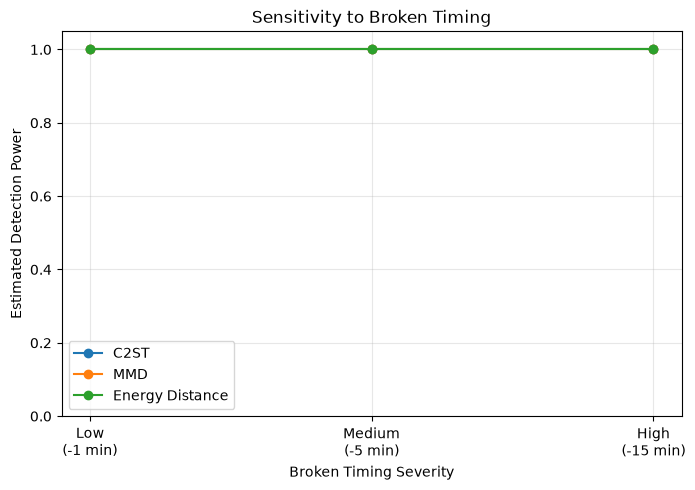

In [83]:
# sensitivity curve 
import matplotlib.pyplot as plt

plot_order = [
    "low",
    "medium",
    "high"
]

x_positions = [0, 1, 2]

x_labels = [
    "Low\n(-1 min)",
    "Medium\n(-5 min)",
    "High\n(-15 min)"
]

plt.figure(
    figsize=(8, 5)
)

for metric in [
    "C2ST",
    "MMD",
    "Energy Distance"
]:

    powers = []

    for level in plot_order:

        value = (
            broken_timing_power_summary[
                (
                    broken_timing_power_summary[
                        "level"
                    ] == level
                )
                &
                (
                    broken_timing_power_summary[
                        "metric"
                    ] == metric
                )
            ]["power"]
            .iloc[0]
        )

        powers.append(value)

    plt.plot(
        x_positions,
        powers,
        marker="o",
        label=metric
    )


plt.xticks(
    x_positions,
    x_labels
)

plt.xlabel(
    "Broken Timing Severity"
)

plt.ylabel(
    "Estimated Detection Power"
)

plt.title(
    "Sensitivity to Broken Timing"
)

plt.ylim(
    0,
    1.05
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

#### Broken Timing Pilot Result

The paired sensitivity experiment was conducted using 200 repetitions, 100 campaign pairs per repetition, and low, medium, and high timing violations corresponding to target gaps of −1, −5, and −15 minutes. C2ST, MMD, and Energy Distance achieved an observed power of 1.00 at all three levels. This confirms that the generic 13-feature structural representation preserves enough information for all three metrics to detect Broken Timing without defect-specific timing indicators. However, the flat sensitivity curve indicates that the current magnitude-based severity levels are already above the detectable threshold. Even the −1 minute condition requires replacing an originally positive inter-message gap with a negative one, producing a substantial structural change. Therefore, for the final experiment, Broken Timing severity will be defined primarily through the proportion of affected campaigns while keeping the magnitude of the timing violation fixed. This should provide a more informative graded sensitivity experiment.

In [84]:
broken_timing_sensitivity_df.to_csv(
    "../results/broken_timing_sensitivity_200_runs.csv",
    index=False
)

broken_timing_power_summary.to_csv(
    "../results/broken_timing_sensitivity_200_summary.csv",
    index=False)
